# PMSM Field-Oriented Control: Transforms, Current Loops, Decoupling and the Voltage Limit

`10_pmsm_foc` | level 4 | experiment id(s): `exp_10_pmsm_foc`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 5 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Verify Clarke and Park transforms (amplitude-invariant), the 1.5 power factor, and SVPWM
  (min-max injection) against closed-form properties, including the 2/sqrt(3) voltage-utilisation gain over
  sinusoidal PWM.
- Check a PMSM dq model against its algebraic steady state and against three-phase power.
- Design dq current PI controllers by pole-zero cancellation, and measure the rise time against the
  design value and the effect of decoupling and delay compensation.
- Close a speed loop with a current limit, and show what the inverter voltage limit does to the speed and to the d-axis current.

## 2. Real-World Engineering Problem

Field-oriented control makes an AC machine behave like a DC machine: torque follows the q-axis
current, and the d-axis current is held at zero or used to weaken the field. Getting there
involves coordinate transforms, current loops fighting cross-coupling that grows with speed, and
a voltage limit that fixes the highest speed without field weakening. Each of these can be checked against a
closed-form result before any controller is judged.

## 3. Research Background

The dq transformation goes back to Park (1929); the machine model in this form is standard
(Krause et al., 2013; Pillay and Krishnan, 1989); space-vector PWM is described by
van der Broeck, Skudelny and Stanke (1988). Section 4 lists what was verified.

## 4. Research Literature

Sources are cited for the transforms, the machine model and the PWM method. No numbers are
taken from them; the machine parameters are illustrative and the experiments are simulations.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| park1929 | Park, R. H. (1929). Two-reaction theory of synchronous machines: generalized method of analysis, Part I. Transactions of the AIEE, 48(3), 716-727. doi:10.1109/T-AIEE.1929.5055275. | Origin of the d-q reference-frame transformation. | Historical; modern drives use the amplitude-invariant form defined by convention. | verified (2026-11-25, web search of publisher/index/library record). Index records agree on volume, issue and pages. |
| vdb1988 | van der Broeck, H. W.; Skudelny, H.-C.; Stanke, G. V. (1988). Analysis and realization of a pulsewidth modulator based on voltage space vectors. IEEE Transactions on Industry Applications, 24(1), 142-150. doi:10.1109/28.87265. | Space-vector PWM and its relation to carrier-based modulation with common-mode injection. | The min-max injection used here is the carrier-based equivalent, not a line-by-line reproduction. | verified (2026-11-25, web search of publisher/index/library record). Index record gives venue, volume, issue, pages and DOI. |
| pillay1989 | Pillay, P.; Krishnan, R. (1989). Modeling, simulation, and analysis of permanent-magnet motor drives, Part II: The brushless DC motor drive. IEEE Transactions on Industry Applications, 25(2), 274-279. doi:10.1109/28.25542. | Phase-variable BLDC model with trapezoidal back-EMF used for drive simulation. | Abstract-level verification only; the equations used here were written independently from the standard model. | verified (2026-11-25, web search of publisher/index/library record). Index record gives venue, volume, issue, pages and DOI. |
| krause2013 | Krause, P. C.; Wasynczuk, O.; Sudhoff, S. D.; Pekarek, S. D. (2013). Analysis of Electric Machinery and Drive Systems, 3rd ed.. Wiley-IEEE Press. ISBN 978-1-118-02429-4. | Reference-frame theory, PMSM and BLDC models, averaged converter models. | Textbook; parameters for a specific machine must come from its datasheet. | verified (2026-11-25, web search of publisher/index/library record). Publisher-affiliated page and a retailer record agree on edition, year and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

**Transforms (amplitude-invariant).** $\alpha=\tfrac23(a-\tfrac12b-\tfrac12c)$, $\beta=(b-c)/\sqrt3$;
$d=\alpha\cos\theta+\beta\sin\theta$, $q=-\alpha\sin\theta+\beta\cos\theta$. A balanced set of amplitude $A$ maps to
$(A,0)$ in dq at its own angle. Instantaneous power: $p=v_ai_a+v_bi_b+v_ci_c=\tfrac32(v_di_d+v_qi_q)$ for zero-sequence-free sets.

**Machine (surface magnets, $L_d=L_q=L$).**
$$L\dot i_d=v_d-R_si_d+\omega_eLi_q,\quad L\dot i_q=v_q-R_si_q-\omega_eLi_d-\omega_e\psi,\quad T_e=\tfrac32p\psi i_q,\quad J\dot\omega_m=T_e-B\omega_m-T_l.$$
**Algebraic steady state** at constant $v_{dq}$ and $\omega_e$:
$\begin{bmatrix}R_s&-\omega_eL\\\omega_eL&R_s\end{bmatrix}\begin{bmatrix}i_d\\i_q\end{bmatrix}=\begin{bmatrix}v_d\\v_q-\omega_e\psi\end{bmatrix}$.

**Current loop.** Decoupling $v_d\mathrel{-}=\omega_eLi_q$, $v_q\mathrel{+}=\omega_e(Li_d+\psi)$ leaves $1/(Ls+R_s)$; PI with $k_p=L\omega_c$, $k_i=R_s\omega_c$
gives $1/(s/\omega_c+1)$ with 10-90% rise time $2.197/\omega_c$ (continuous time; sampling and the one-sample delay slow it).

**SVPWM (min-max).** Add $-\tfrac12(\max+\min)$ of the three phase references. The linear limit is
$V_{dc}/\sqrt3$ (circle), against $V_{dc}/2$ for sinusoidal PWM: ratio $2/\sqrt3=1.1547$.

**Voltage limit.** Without field weakening ($i_d=0$) the voltage needed at speed $\omega_m$ and torque current $i_q$ is
$|v|^2=(R_si_q+p\omega_m\psi)^2+(p\omega_mLi_q)^2$; the highest steady speed **with $i_d$ held at zero** is where $|v|=V_{dc}/\sqrt3$. When the voltage limiter scales the vector instead, $i_d$ is no longer controlled to zero and the speed can differ; the experiment measures this.

## 6. System Modeling

Illustrative machine (library defaults): `Rs = 0.35 ohm`, `Ld = Lq = 1.2 mH`, `psi = 0.015 Wb`, 4 pole pairs,
`J = 5e-5`, `B = 1e-5`, `Vdc = 48 V` (so `Vlin = 27.7 V`). Torque constant `kt = 1.5 p psi = 0.09 N m/A`.
Averaged inverter, controller period 100 microseconds, internal RK4 with 2 substeps. Phase currents are measured
(ideal) and transformed to dq; the voltage vector is held over one period and rotated at the instantaneous
rotor angle inside the integrator, so the sampling delay is in the model.

## 7. Dataset and Measurement Data

No dataset; simulated machine. No measurement noise.

## 8. Algorithm Architecture

Controller: speed PI (1 kHz, output iq reference limited to +-10 A) feeding two dq current PI loops
(10 kHz) with decoupling, voltage circle limit at `Vdc/sqrt(3)` and back-calculation anti-windup
(library `DQCurrentController`). Optional angle advance compensates the delay between computing and applying the voltage.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import PID
from control_lab.controllers.foc import DQCurrentController, speed_loop_gains
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import step_response_metrics
from control_lab.motors import PMSM, PMSMParams
from control_lab.transforms import SQRT3, clarke, duties_to_alpha_beta, inv_clarke, inv_park, park, svpwm
from scipy.optimize import brentq
import pandas as pd

EXP = "exp_10_pmsm_foc"
SEED = 20261125
P0 = PMSMParams()
TS, RATIO, I_MAX = 1e-4, 10, 10.0
VLIN = P0.Vdc / SQRT3

def iq_step_metrics(o, amp=5.0, t_on=0.002):
    # step metrics relative to the q-current at the instant of the step (it can be non-zero when the plant differs from the design)
    k0 = int(round(t_on / TS)); y0 = float(o["iq"][k0]); sel = o["t"] >= t_on
    return step_response_metrics(o["t"][sel], o["iq"][sel], amp, y_initial=y0), sel

def simulate(t_end, plant=P0, ctl_par=P0, w_ref=0.0, iq_step=None, tl=0.0, w0=0.0, hold=False, decouple=True, adv=0.0, bw=300.0, f_speed=30.0):
    # hold=True: huge inertia keeps the speed at w0 (current-loop tests); iq_step=(t_on, iq_amp) bypasses the speed loop
    pl = plant.with_changes(J=plant.J * 1000) if hold else plant
    m = PMSM(pl, Ts=TS, substeps=2); m.reset(); m.x[2] = w0
    cur = DQCurrentController(ctl_par.Ld, ctl_par.Lq, ctl_par.Rs, ctl_par.psi, TS, bw, VLIN, decouple=decouple)
    kp_w, ki_w = speed_loop_gains(ctl_par.J, ctl_par.kt, f_speed)
    spd = PID(kp_w, ki_w, Ts=RATIO * TS, u_min=-I_MAX, u_max=I_MAX, antiwindup="backcalc")
    n = int(round(t_end / TS)); iq_ref = 0.0
    keys = ("t", "w", "id", "iq", "vd", "vq", "iq_ref", "te", "vmag", "sat")
    out = {k: np.empty(n) for k in keys}
    for k in range(n):
        ia, ib, ic = m.phase_currents(); al, be = clarke(ia, ib, ic); id_, iq = park(al, be, m.theta_e)
        if iq_step is not None: iq_ref = iq_step[1] if k * TS >= iq_step[0] else 0.0
        elif k % RATIO == 0: iq_ref = spd.update(w_ref, m.y)
        vd, vq = cur.update(0.0, iq_ref, id_, iq, m.omega_e)
        va, vb = inv_park(vd, vq, m.theta_e + adv * m.omega_e * TS)
        duty, sc = svpwm(va, vb, P0.Vdc); va, vb = duties_to_alpha_beta(duty, P0.Vdc)
        for key, val in zip(keys, (k * TS, m.y, id_, iq, vd, vq, iq_ref, m.torque(), np.hypot(vd, vq), float(cur.saturated))):
            out[key][k] = val
        m.step(va, vb, tl if np.isscalar(tl) else tl[k])
    return out

`simulate` measures phase currents, transforms them to dq, runs the controllers, and applies the voltage through
SVPWM (so the linear limit is part of the loop).

## 10. Simulation and Numerical Analysis

Sections 11 to 13 run: transform and PWM properties, machine checks, the current-loop study
(decoupling x delay compensation, held speed 200 rad/s, and a parameter-mismatch case), the speed loop with a load step,
and the voltage-limited speed test.

## 11. Experimental Validation

Level: **software simulation**. References: closed-form transform and power properties, the algebraic
steady state of the dq equations, the current-loop design rise time and the voltage-limit speed root. These test
the model and the design formulas. No inverter, encoder or machine was used.

## 12. Performance Evaluation

In [3]:
checks = []
rng = np.random.default_rng(SEED)
# 1. transforms
th = rng.uniform(-np.pi, np.pi, 200); A = 7.0
a, b, c = A * np.cos(th), A * np.cos(th - 2 * np.pi / 3), A * np.cos(th + 2 * np.pi / 3)
al, be = clarke(a, b, c); d, q = park(al, be, th)
checks.append(check("balanced set of amplitude 7: |alpha,beta| = 7 and dq = (7, 0) at its own angle", np.allclose(np.hypot(al, be), A) and np.allclose(d, A) and np.allclose(q, 0, atol=1e-12), "200 random angles"))
x = rng.normal(size=(200, 2)); ang = rng.uniform(-np.pi, np.pi, 200)
back = inv_park(*park(x[:, 0], x[:, 1], ang), ang); abc = inv_clarke(x[:, 0], x[:, 1]); back2 = clarke(*abc)
checks.append(check("park/inv_park and clarke/inv_clarke round trips (error < 1e-12)", np.allclose(back[0], x[:, 0], atol=1e-12) and np.allclose(back[1], x[:, 1], atol=1e-12) and np.allclose(back2[0], x[:, 0], atol=1e-12) and np.allclose(back2[1], x[:, 1], atol=1e-12), "random vectors"))
v = inv_clarke(*rng.normal(size=(2, 200))); i_ = inv_clarke(*rng.normal(size=(2, 200)))
p3 = v[0] * i_[0] + v[1] * i_[1] + v[2] * i_[2]
vv = clarke(*v); ii = clarke(*i_); thr = rng.uniform(-np.pi, np.pi, 200); vdq = park(*vv, thr); idq = park(*ii, thr)
checks.append(check("three-phase power equals 1.5 (vd id + vq iq) for zero-sequence-free sets", np.allclose(p3, 1.5 * (vdq[0] * idq[0] + vdq[1] * idq[1]), atol=1e-10), f"max error {np.max(np.abs(p3 - 1.5 * (vdq[0] * idq[0] + vdq[1] * idq[1]))):.1e}"))
# 2. SVPWM
angs = np.linspace(0, 2 * np.pi, 721); worst = 0.0; lin_ok = True
for amp in (0.5 * VLIN, 0.99 * VLIN):
    for t in angs:
        duty, sc = svpwm(amp * np.cos(t), amp * np.sin(t), P0.Vdc)
        lin_ok &= (sc == 1.0) and duty.min() >= -1e-12 and duty.max() <= 1 + 1e-12
        ra, rb = duties_to_alpha_beta(duty, P0.Vdc); worst = max(worst, abs(ra - amp * np.cos(t)), abs(rb - amp * np.sin(t)))
checks.append(check("SVPWM: duties within [0,1] and the realised vector equals the request up to 0.99 Vdc/sqrt3", lin_ok and worst < 1e-10, f"max vector error {worst:.1e}"))
over = min(svpwm(1.05 * VLIN * np.cos(t), 1.05 * VLIN * np.sin(t), P0.Vdc)[1] for t in angs)
checks.append(check("SVPWM shortens a request 5% above Vdc/sqrt3 (scale < 1) and keeps duties valid", over < 1.0, f"min scale {over:.4f}"))
a_spwm = P0.Vdc / 2; checks.append(check("voltage utilisation: SVPWM linear limit / sinusoidal PWM limit = 2/sqrt(3)", abs(VLIN / a_spwm - 2 / SQRT3) < 1e-12, f"{VLIN / a_spwm:.5f}"))

# 3. machine: algebraic steady state at held speed and fixed voltage
w0, vd0, vq0 = 150.0, 2.0, 12.0
we = P0.p * w0; Mx = np.array([[P0.Rs, -we * P0.Lq], [we * P0.Ld, P0.Rs]]); sol = np.linalg.solve(Mx, [vd0, vq0 - we * P0.psi])
m = PMSM(P0.with_changes(J=P0.J * 1e6, B=0.0), Ts=TS, substeps=2); m.x[2] = w0
for k in range(int(0.1 / TS)):
    ang_ = m.theta_e + 0.5 * m.omega_e * TS; va, vb = inv_park(vd0, vq0, ang_); m.step(va, vb, 0.0)   # half-period advance: the held vector rotates by we*Ts across one step
checks.append(check("dq steady state equals the algebraic solution (id, iq within 0.5%)", np.allclose(m.x[:2], sol, rtol=5e-3, atol=2e-3), f"sim {np.round(m.x[:2], 4)} vs {np.round(sol, 4)} A"))
p_el = 1.5 * (vd0 * m.x[0] + vq0 * m.x[1]); p_cu = 1.5 * P0.Rs * (m.x[0] ** 2 + m.x[1] ** 2); p_mech = m.torque() * w0
p_scale = max(abs(p_el), abs(p_cu), abs(p_mech))     # the balance is a difference of terms of about 10 W, so the error is judged against the largest term
checks.append(check("electrical power = copper loss + mechanical power at steady state (error < 0.5% of the largest term)", abs(p_el - p_cu - p_mech) / p_scale < 5e-3, f"{p_el:.3f} = {p_cu:.3f} + {p_mech:.3f} W, residual {p_el - p_cu - p_mech:.4f} W"))
# direct comparison of the transform path with the model state, over a dynamic run
m = PMSM(P0.with_changes(J=P0.J * 1000), Ts=TS, substeps=2); m.x[2] = 100.0; mx = 0.0
for k in range(500):
    ia, ib, ic = m.phase_currents(); al, be = clarke(ia, ib, ic); d_, q_ = park(al, be, m.theta_e)
    mx = max(mx, abs(d_ - m.x[0]), abs(q_ - m.x[1])); va, vb = inv_park(1.0 * (k > 50), 5.0, m.theta_e); m.step(va, vb, 0.0)
checks.append(check("dq from measured phase currents equals the model state (max error < 1e-9 A)", mx < 1e-9, f"{mx:.1e} A"))

# 4. current loop: rise time at standstill against the design value
bw = 300.0; wc = 2 * np.pi * bw
o = simulate(0.02, iq_step=(0.002, 5.0), w0=0.0, hold=True, decouple=True, adv=1.5, bw=bw)
sm, sel = iq_step_metrics(o)
rt_th = 2.197 / wc; rt_meas = sm["rise_time_10_90"]
checks.append(check("current-loop rise time at standstill within 25% of 2.197/wc", abs(sm["rise_time_10_90"] - rt_th) / rt_th < 0.25, f"{sm['rise_time_10_90']*1e3:.3f} ms vs {rt_th*1e3:.3f} ms"))
# 5. decoupling and delay compensation at 200 rad/s
cc = []
for dec in (False, True):
    for adv in (0.0, 1.5):
        o = simulate(0.02, iq_step=(0.002, 5.0), w0=200.0, hold=True, decouple=dec, adv=adv, bw=bw)
        sm, s_ = iq_step_metrics(o)
        cc.append(dict(decoupling=dec, angle_advance=adv, rise_ms=sm["rise_time_10_90"] * 1e3, overshoot_percent=sm["overshoot_percent"], peak_abs_id_A=float(np.max(np.abs(o["id"][s_]))), id_final_A=float(o["id"][-1])))
dcc = pd.DataFrame(cc); print(dcc.round(3).to_string(index=False))
r_off, r_on = dcc[(~dcc.decoupling) & (dcc.angle_advance == 1.5)].peak_abs_id_A.iloc[0], dcc[(dcc.decoupling) & (dcc.angle_advance == 1.5)].peak_abs_id_A.iloc[0]
checks.append(check("decoupling cuts the d-axis excursion after a 5 A iq step by at least a factor 3 (200 rad/s)", r_off > 3 * r_on, f"{r_off:.3f} A without, {r_on:.3f} A with"))
# 6. parameter mismatch
mm = {}
for name, pl in {"nominal": P0, "Rs x1.5": P0.with_changes(Rs=1.5 * P0.Rs), "L x0.7": P0.with_changes(Ld=0.7 * P0.Ld, Lq=0.7 * P0.Lq), "psi x0.85": P0.with_changes(psi=0.85 * P0.psi)}.items():
    o = simulate(0.02, plant=pl, ctl_par=P0, iq_step=(0.002, 5.0), w0=200.0, hold=True, decouple=True, adv=1.5, bw=bw)
    sm, s_ = iq_step_metrics(o)
    mm[name] = dict(rise_ms=sm["rise_time_10_90"] * 1e3, overshoot_percent=sm["overshoot_percent"], peak_abs_id_A=float(np.max(np.abs(o["id"][s_]))), iq_final_A=float(o["iq"][-1]), id_final_A=float(o["id"][-1]))
print(pd.DataFrame(mm).T.round(3))

 decoupling  angle_advance  rise_ms  overshoot_percent  peak_abs_id_A  id_final_A
      False            0.0    5.247              0.613          1.266       0.047
      False            1.5    5.819              0.333          1.138       0.062
       True            0.0    1.011              0.939          0.281       0.000
       True            1.5    1.155              0.000          0.322      -0.002
           rise_ms  overshoot_percent  peak_abs_id_A  iq_final_A  id_final_A
nominal      1.155              0.000          0.322       4.999      -0.002
Rs x1.5      1.592              0.000          0.312       4.995      -0.004
L x0.7       0.966              0.031          0.650       5.002      -0.009
psi x0.85    0.859              2.905          0.287       5.002      -0.002


Check 5 is a prediction I made before running (decoupling should shrink the cross-axis excursion by a large factor).
The mismatch table shows how much the nominal design tolerates; the integrators remove steady-state error,
so the transient excursion is the quantity of interest.

In [4]:
# 7. speed loop with a load step
n_t = int(round(0.6 / TS)); tl_arr = np.where(np.arange(n_t) * TS >= 0.3, 0.1, 0.0)
o = simulate(0.6, w_ref=200.0, tl=tl_arr, bw=bw, adv=1.5)
sp = step_response_metrics(o["t"][:int(0.3 / TS)], o["w"][:int(0.3 / TS)], 200.0)
iq_ss = (0.1 + P0.B * 200.0) / P0.kt; iq_mean = float(np.mean(o["iq"][-int(0.05 / TS):])); id_mean = float(np.mean(o["id"][-int(0.05 / TS):]))
checks.append(check("speed loop: zero steady-state speed error before and after the load step (<0.2%)", abs(o["w"][int(0.3 / TS) - 1] - 200) / 200 < 2e-3 and abs(o["w"][-1] - 200) / 200 < 2e-3, f"{o['w'][int(0.3 / TS) - 1]:.3f}, {o['w'][-1]:.3f} rad/s"))
checks.append(check("steady iq equals (Tl + B w)/kt within 2% and id is below 0.05 A", abs(iq_mean - iq_ss) / iq_ss < 0.02 and abs(id_mean) < 0.05, f"iq {iq_mean:.4f} vs {iq_ss:.4f} A, id {id_mean:.4f} A"))
checks.append(check("torque-producing current stays within 10% of the 10 A limit", np.max(np.abs(o["iq"])) < 1.10 * I_MAX, f"peak iq {np.max(np.abs(o['iq'])):.2f} A"))
checks.append(check("commanded voltage magnitude never exceeds the linear limit Vdc/sqrt3", np.max(o["vmag"]) <= VLIN * (1 + 1e-9), f"peak {np.max(o['vmag']):.3f} V vs {VLIN:.3f} V"))
speed_m = dict(overshoot_percent=sp["overshoot_percent"], settling_ms=None if sp["settling_time"] is None else sp["settling_time"] * 1e3, peak_iq_A=float(np.max(np.abs(o["iq"]))), load_dip_rad_s=float(200 - o["w"][int(0.3 / TS):].min()))
print(speed_m)
run_speed = o

# 8. behaviour at the voltage limit
def v_alg(w, id_, iq):
    we_ = P0.p * w
    return np.hypot(P0.Rs * id_ - we_ * P0.Lq * iq, P0.Rs * iq + we_ * (P0.Ld * id_ + P0.psi))
w_bound_id0 = brentq(lambda w: v_alg(w, 0.0, P0.B * w / P0.kt) - VLIN, 100, 2000)     # highest speed if id were held at zero
o2 = simulate(1.0, w_ref=700.0, bw=bw, adv=1.5)
last = slice(-int(0.1 / TS), None)
w_top_sim, id_top, iq_top = float(np.mean(o2["w"][last])), float(np.mean(o2["id"][last])), float(np.mean(o2["iq"][last]))
w_pred_id = brentq(lambda w: v_alg(w, id_top, P0.B * w / P0.kt) - VLIN, 100, 3000)    # speed at which the measured id reaches the limit
checks.append(check("at the voltage limit the controller reports saturation", float(np.mean(o2["sat"][last])) > 0.5, f"saturated fraction {float(np.mean(o2['sat'][last])):.2f}"))
checks.append(check("steady state at the limit: the algebraic voltage of the measured (id, iq, w) equals Vdc/sqrt3 (<1%)", abs(v_alg(w_top_sim, id_top, iq_top) - VLIN) / VLIN < 0.01, f"{v_alg(w_top_sim, id_top, iq_top):.3f} V vs {VLIN:.3f} V"))
checks.append(check("steady state at the limit: iq equals B w / kt (within 0.02 A)", abs(iq_top - P0.B * w_top_sim / P0.kt) < 0.02, f"{iq_top:.4f} vs {P0.B * w_top_sim / P0.kt:.4f} A"))
checks.append(check("speed equals the voltage-limit root evaluated with the measured id (within 2%)", abs(w_top_sim - w_pred_id) / w_pred_id < 0.02, f"{w_top_sim:.1f} vs {w_pred_id:.1f} rad/s"))
checks.append(check("the limiter pushed id negative (unintended field weakening, id < -0.5 A)", id_top < -0.5, f"id = {id_top:.3f} A"))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], "|", c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

{'overshoot_percent': 11.788657493808397, 'settling_ms': 30.700000000000003, 'peak_iq_A': 9.978963606634338, 'load_dip_rad_s': 4.6550820515819}


20 of 20 checks passed


## 13. Visualization and Interpretation

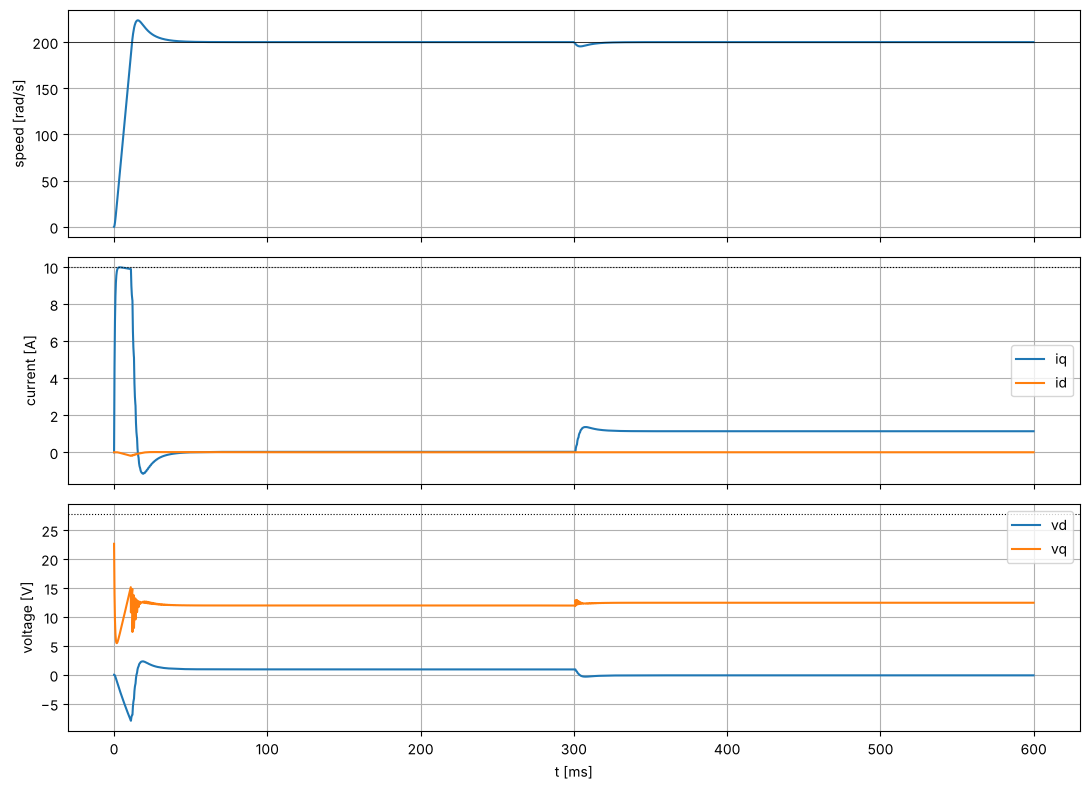

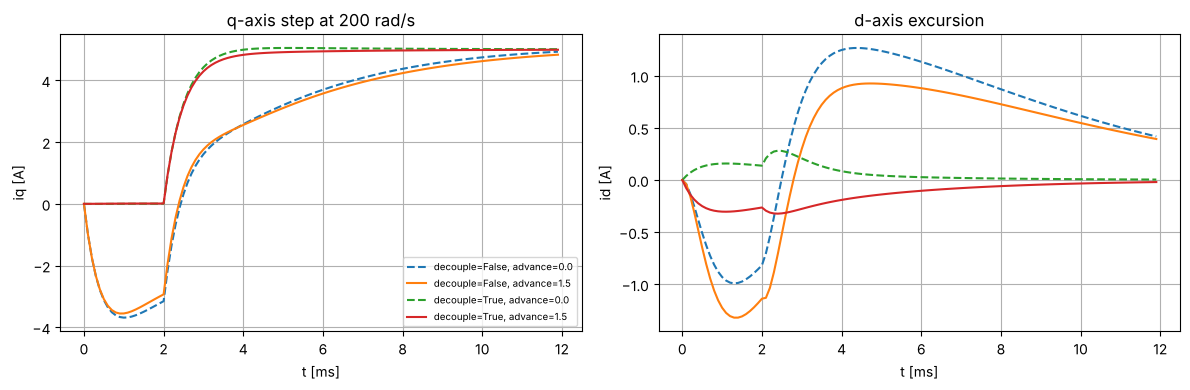

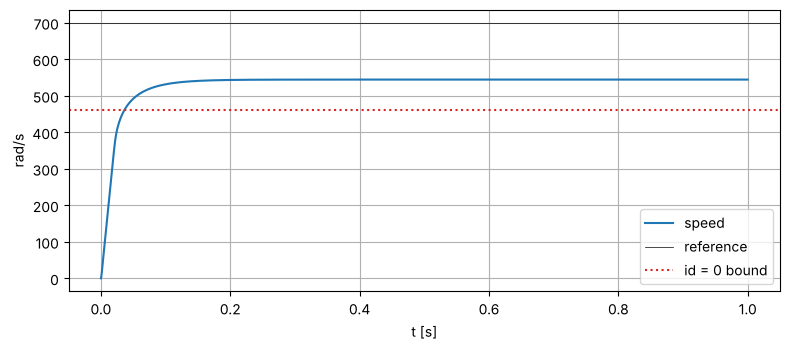

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(run_speed["t"] * 1e3, run_speed["w"]); ax[0].axhline(200, color="k", lw=0.5); ax[0].set(ylabel="speed [rad/s]")
ax[1].plot(run_speed["t"] * 1e3, run_speed["iq"], label="iq"); ax[1].plot(run_speed["t"] * 1e3, run_speed["id"], label="id"); ax[1].axhline(I_MAX, color="k", ls=":", lw=0.8); ax[1].legend(); ax[1].set(ylabel="current [A]")
ax[2].plot(run_speed["t"] * 1e3, run_speed["vd"], label="vd"); ax[2].plot(run_speed["t"] * 1e3, run_speed["vq"], label="vq"); ax[2].axhline(VLIN, color="k", ls=":", lw=0.8); ax[2].legend(); ax[2].set(ylabel="voltage [V]", xlabel="t [ms]")
fig.tight_layout(); figs = [save_figure(fig, EXP, "speed_loop")]
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for dec in (False, True):
    for adv, ls in ((0.0, "--"), (1.5, "-")):
        o = simulate(0.012, iq_step=(0.002, 5.0), w0=200.0, hold=True, decouple=dec, adv=adv, bw=bw)
        ax[0].plot(o["t"] * 1e3, o["iq"], ls, label=f"decouple={dec}, advance={adv}"); ax[1].plot(o["t"] * 1e3, o["id"], ls)
ax[0].set(xlabel="t [ms]", ylabel="iq [A]", title="q-axis step at 200 rad/s"); ax[0].legend(fontsize=7); ax[1].set(xlabel="t [ms]", ylabel="id [A]", title="d-axis excursion")
fig.tight_layout(); figs.append(save_figure(fig, EXP, "decoupling_and_delay"))
plt.show()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(o2["t"], o2["w"], label="speed"); ax.axhline(700, color="k", lw=0.5, label="reference"); ax.axhline(w_bound_id0, color="C3", ls=":", label="id = 0 bound")
ax.set(xlabel="t [s]", ylabel="rad/s"); ax.legend(); fig.tight_layout(); figs.append(save_figure(fig, EXP, "voltage_limited_speed"))
plt.show()

The decoupling figure shows two separate effects: cross-coupling (solid versus dashed lines of
decouple=True/False) and the sampling delay (angle advance 0 versus 1.5 sample periods).

## 14. Research Discussion and Limitations

**Facts from this run.**
- **Transforms and PWM.** Clarke/Park round trips and the 1.5 power factor hold to 3e-15; SVPWM reproduces the request to
  1e-14 inside the linear range, shortens requests above `Vdc/sqrt(3)`, and its linear limit is 2/sqrt(3) times the
  sinusoidal PWM limit.
- **Sampling delay matters in the model and in the test.** The voltage vector is held in the stationary frame for one period, so
  in dq it rotates by `we Ts` across the step. At 150 rad/s that is 3.4 degrees, 1.7 degrees on average. My first steady-state
  test ignored it and measured `iq = -1.05 A` against the algebraic `-0.61 A`, a 72% error, because `iq` is the small difference
  between a 12 V command and a 9 V back-EMF. With a half-period angle advance the simulation gives -0.6100 A against -0.6085 A. The
  model was right and my test was wrong.
- **Current loop (300 Hz design).** At standstill the 10-90% rise time is 1.06 ms against 1.17 ms for the continuous design
  (9% faster; the cause was not investigated). At 200 rad/s without decoupling the rise time is 5.2 to 5.8 ms and the d-axis
  excursion 1.1 to 1.3 A; with decoupling 1.0 to 1.2 ms and 0.28 to 0.32 A. The 1.5-sample angle advance removes the
  0.9% overshoot at the price of 0.14 ms rise time.
- **Parameter mismatch (decoupled, controller kept at nominal).** `Rs` x1.5: rise time 1.59 ms (+38%). `L` x0.7: d-axis excursion
  0.65 A (twice nominal). `psi` x0.85: overshoot 2.9%. All reach `iq = 5 A` and `id = 0` at steady state.
- **Speed loop.** 11.8% overshoot, settling 30.7 ms, peak `iq` 9.98 A (limit 10 A), load-step dip 4.7 rad/s, zero steady-state
  error, and `iq` equal to `(Tl + B w)/kt` (1.1339 against 1.1333 A).
- **Voltage limit.** With a 700 rad/s reference the speed settles at 544 rad/s, 18% above the 462 rad/s bound
  computed for `id = 0`. The controller reports saturation continuously, and `id` has gone to -1.89 A: when the circle limiter scales
  the vector, `id` is no longer held at zero, which is unintended field weakening. The algebraic voltage of the measured `(id, iq, w)`
  is 27.77 V against the 27.71 V limit, and the speed root computed with the measured `id` is 543 rad/s, so the numbers are consistent.

**Inference (not tested).** The unintended weakening depends on how the limiter distributes the voltage; a limiter that
prioritises the d axis would behave differently. A real machine at -1.9 A on a surface-magnet rotor is far from
demagnetisation, but that was not modelled.

**Limits.** (1) Averaged inverter: no PWM ripple, dead time, switch drops or current-sensor error. (2) Surface magnets, no
saturation or iron loss. (3) Ideal rotor angle and ideal phase-current measurement. (4) No designed field weakening or MTPA.
(5) One current bandwidth (300 Hz) and one speed (200 rad/s) for the decoupling study. (6) Illustrative parameters; no
hardware.

## 15. Summary, Exercises, and Further Research

**Key insights.** Verify transforms, PWM and the machine model against closed-form properties before tuning any loop; the
inverter voltage limit, not the controller, sets the top speed without field weakening.

**Exercises.** (1) Add field weakening (`id < 0`) and measure the extra speed it buys against the prediction from the
voltage-circle and current-circle intersection. (2) Increase the current bandwidth to 600 Hz and find when the
loop becomes poorly damped. (3) Add an interior-magnet saliency (`Lq > Ld`) and use MTPA. (4) Add a 2-sample current
measurement delay.

**Related.** DC motor (06), BLDC six-step (09), conveyor (11).
**Research directions.** Sensorless FOC, MPC-based current control and torque-ripple reduction.

In [6]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="PMSM field-oriented control: transforms, current loops, decoupling, voltage limit",
    notebook="notebooks/04_motor_control/10_pmsm_foc.ipynb",
    algorithm="Clarke/Park transforms, dq PI current control with decoupling, SVPWM (min-max), speed PI",
    application="Surface-magnet PMSM servo drive (illustrative)", plant_model="PMSM dq model, averaged inverter, RK4",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated machine, illustrative parameters."},
    metrics={"decoupling_delay_study": cc, "parameter_mismatch": mm, "speed_loop": speed_m,
             "voltage_limit": {"top_speed_id0_bound_rad_s": float(w_bound_id0), "top_speed_sim_rad_s": w_top_sim, "id_at_limit_A": id_top, "iq_at_limit_A": iq_top, "top_speed_pred_with_measured_id_rad_s": float(w_pred_id), "v_linear_limit_V": float(VLIN)},
             "current_loop": {"rise_time_ms": float(rt_meas * 1e3), "design_rise_time_ms": float(rt_th * 1e3)}},
    checks=checks, sampling_time_s=TS, random_seed=SEED, number_of_trials=len(cc) + len(mm) + 2,
    controller_parameters={"current_bandwidth_hz": bw, "speed_bandwidth_hz": 30.0, "current_limit_A": I_MAX, "speed_loop_ratio": RATIO},
    plant_parameters=P0.as_dict(), input_configuration={"speed_ref_rad_s": 200.0, "iq_step_A": 5.0},
    disturbance_configuration={"load_step_Nm": 0.1, "at_s": 0.3}, operating_conditions={"held_speed_rad_s": 200.0, "vdc_V": P0.Vdc}, figure_references=figs,
    limitations=["Averaged inverter: no PWM ripple, dead time, switch drops or current-sensor error.",
                 "Surface magnets (Ld = Lq), no saturation, no iron loss, no cogging.",
                 "Ideal rotor angle and phase-current measurement.", "No field weakening or MTPA.",
                 "Illustrative parameters; no measured data.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_10_pmsm_foc.json
